![uc3m](http://materplat.org/wp-content/uploads/LogoUC3M.jpg)
#### Mount Google Drive

In [ ]:
# If you want to store some models or results into your drive, you might find these lines of code useful
# Load the Drive helper and mount
from google.colab import drive

# This will prompt for authorization.
drive.mount('/content/drive')

# Change to assignment directory ('ATVAIV/LabSession1' by default)
import os
os.chdir('/content/drive/My Drive/ATVAIV/LabSession1')


Mounted at /content/drive


#### Required libraries for the lab session

In [ ]:
# Numpy
import numpy  as np

# Matplotlib
import matplotlib.pyplot as plt
plt.style.use('default')

# Itertools
import itertools

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F  # useful stateless functions
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import sampler

import torchvision.datasets as dset
import torchvision.transforms as T

## [!] INSTRUCTIONS FOR THE SUBMISSION OF THE LAB EXERCISES

The objective of this activity is that students strengthen the concepts acquired about Image Classification using DNNs and CNNs.

In order to do the lab session exercises, students have to use Google Colab, execute this notebook for their resolution and answer several brief questions, including both extra code and text cells, if necessary.

**This notebook with the solutions to the lab exercises must 30th October at 23:59h.**


# LAB SESSION 1
---

# IMAGE CLASSIFICATION WITH DNNs AND CNNs

### APPLICATIONS OF SPEECH, AUDIO, IMAGE AND VIDEO PROCESSING

### MASTER IN TELECOMMUNICATIONS ENGINEERING
### ACADEMIC COURSE 2026/2027



1. INTRODUCTION AND OBJECTIVES

2. DATABASE

> 2.1 PREPARATION

> 2.2 VISUALIZATION

3. MULTILAYER PERCEPTRON

> Module API

> 3.1 NEURAL NETWORK DEFINITION

> 3.2 TRAINING LOOP AND EXECUTION

4. CONVOLUTIONAL NEURAL NETWORKS

> Module API

> 4.1 NEURAL NETWORK DEFINITION

> 4.2 TRAINING LOOP AND EXECUTION

> 4.3 SHOW WHAT HAS BEEN LEARNED BY THE CNN


---
## 1. INTRODUCTION AND OBJECTIVES
---

This lab session makes an introduction to the use of neural networks for image classification.

For that purpose, we will make use of the [PyTorch](https://pytorch.org/) open source machine learning framework. PyTorch is a system for executing dynamic computational graphs over Tensor objects that behave similarly as numpy ndarray. It comes with a powerful automatic differentiation engine that removes the need for manual back-propagation.

Moreover, the well-known [CIFAR-10 database](https://www.cs.toronto.edu/~kriz/cifar.html), which consists of 60000 32x32 colour images in 10 classes, will be used. The objective will be to classify these images according to the class they belong to. Therefore, we will solve a multi-class classification problem with 10 classes.


---
## 2. DATABASE
---

The [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) dataset consists of 60000 32x32 colour images in 10 classes, with 6000 images per class. There are 50000 training images (5000 images per class) and 10000 test images (1000 images per class). The training set is further divided into 49000 images for training and the remaining 1000 images for validation.

Here are the classes in the dataset, as well as 10 random images from each:

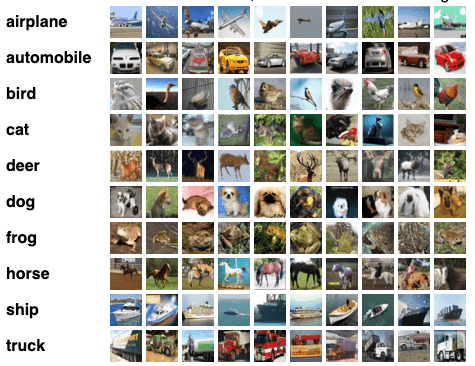


---
#### 2.1 PREPARATION
---

First, we load the CIFAR-10 dataset. PyTorch provides convenient tools to automate this process for us. This might take a couple minutes the first time you do it, but the files should stay cached after that.

In [ ]:
# Parameters (to modify if needed)
NUM_TRAIN = 49000 # Number of training images. Queremos usar 49000 imagenes para ENTRENAMIENTO.
b_s = 64 # Batch size. Para entrenar las redes, dividimos el total en lotes, en este caso de 64 imagenes por batch.
#Con lotes de 64, para 49000 imagenes, tendremos 766 lotes. 765 lotes completos y uno con 40.
#A cada recorrido completo por los datos de entrenamiento se le llama época (epoch)

# The torchvision.transforms package provides tools for preprocessing data
# and for performing data augmentation; here we set up a transform to
# preprocess the data by subtracting the mean RGB value and dividing by the
# standard deviation of each RGB value; we've hardcoded the mean and std.
transform = T.Compose([
                T.ToTensor(),
                T.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
            ])
# Antes de introducir las imágenes en la red neuronal, las convertimos a un formato numérico adecuado y normalizamos sus valores.
# Con T.toTensor, convertimos las imagenes en tensores de PyTorch, que son estructuras similares a matrices con las que podemos operar.
# Además, para imágenes RGB de 8 bits, convierte los valores de los píxeles del rango 0–255 al rango 0–1.
# Después, normalizamos los valores de los píxeles. La operación que se hace es: x_{norm} = (x - μ)/(σ)
# Donde x es el valor del pixel después de pasarse a tensor, μ es la media dle canal de color y σ es su desviación estandar.
# En este caso, (0.4914, 0.4822, 0.4465) es la media de los canales RGB y (0.2023, 0.1994, 0.2010) es la desviación estándar.
# Haemos esto porque ayuda a que los datos tengan una escala más adecuada para el entrenamiento de la red neuronal, lo que puede favorecer un aprendizaje más estable.
# T.Compose([]) simplemente encadena las transformaciones en orden: primero convierte la imagen en tensor y después la normaliza.


# We set up a Dataset object for each split (train / val / test); Datasets load
# training examples one at a time, so we wrap each Dataset in a DataLoader which
# iterates through the Dataset and forms minibatches. We divide the CIFAR-10
# training set into train and val sets by passing a Sampler object to the
# DataLoader telling how it should sample from the underlying Dataset.
cifar10_train = dset.CIFAR10('./dataset', train=True, download=True,
                             transform=transform)
# Aquí creamos un objeto Dataset, que representa el conjunto de datos de entrenamiento.
# './dataset': carpeta en la que se guardará o buscará la base de datos.
# train=True: queremos la partición oficial de entrenamiento de CIFAR-10, que contiene 50.000 imágenes.
# download=True: si los archivos no están disponibles localmente, PyTorch intenta descargarlos.
# transform=transform: cada imagen se transforma con las operaciones que acabamos de definir.


loader_train = DataLoader(cifar10_train, batch_size=b_s,
                          sampler=sampler.SubsetRandomSampler(range(NUM_TRAIN)))
# Ya tenemos un Dataset con 50.000 imágenes. Ahora necesitamos un mecanismo que nos las vaya entregando en lotes para poder entrenar la red.
# cifar10_train: el conjunto de imágenes del que obtenemos los datos.
# batch_size=b_s: cada lote contiene hasta 64 imágenes.
# SubsetRandomSampler(range(NUM_TRAIN)): selecciona índices entre 0 y 48.999 y los recorre en orden aleatorio.
# El resultado es que loader_train nos permite obtener lotes aleatorios de esas 49.000 imágenes, junto con sus etiquetas.


cifar10_val = dset.CIFAR10('./dataset', train=True, download=True,
                           transform=transform)
loader_val = DataLoader(cifar10_val, batch_size=b_s,
                        sampler=sampler.SubsetRandomSampler(range(NUM_TRAIN, 50000)))
# Repetimos lo mismo para el conjunto de validación.
# En lugar de seleccionar los índices del 0 al 48.999, utilizamos range(NUM_TRAIN, 50000), seleccionando los índices 49.000 a 49.999


cifar10_test = dset.CIFAR10('./dataset', train=False, download=True,
                            transform=transform)
loader_test = DataLoader(cifar10_test, batch_size=b_s)
# Creamos el conjunto de prueba.
# train=False. Esto le indica a PyTorch que queremos la partición oficial de prueba de CIFAR-10, que contiene 10.000 imágenes.
# En este caso no indicamos un sampler, por lo que el DataLoader utiliza todas las imágenes de prueba, normalmente en orden secuencial.


---
#### 2.2 VISUALIZATION
---

---
### [EXERCISE 1]
---
Visualize a batch of images from the training set:

a) Complete the function 'imshow', which receives an image to visualize as input, in order to unnormalize it first, taking into account the normalization applied during the preparation of the database (see Section 2.1)


/tmp/ipykernel_1200/2483375271.py:7: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  img = (img * std) + mean # reverse the operation Inorm = (Iorig - mu)/sigma


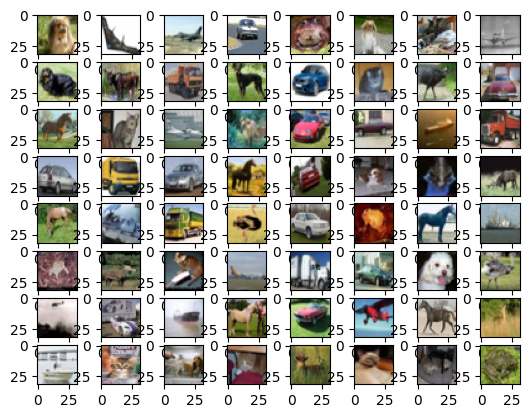

In [ ]:
std = np.array([0.2023, 0.1994, 0.2010])[:,np.newaxis][:,np.newaxis]
mean  = np.array([0.4914, 0.4822, 0.4465])[:,np.newaxis][:,np.newaxis]

# Function to unnormalize and show an image
def imshow(img):
    # - - - WRITE YOUR CODE HERE - - - : a) Unnormalize the image to visualize
    img = (img * std) + mean # reverse the operation Inorm = (Iorig - mu)/sigma
    npimg = img.numpy() # Esta línea convierte un tensor de PyTorch en un array de NumPy
    plt.imshow(np.transpose(npimg, (1, 2, 0))) # Cambiamos el orden de los ejes de canales, altura y anchura a altura, anchura y canales.

# Get a batch of training images
dataiter = iter(loader_train) # Crea un iterador sobre el DataLoader.
images, labels = next(dataiter) # Pide el siguiente elemento disponible del iterador. En este caso, ese elemento es el primer lote de datos que se entrega.

# Show images using subplot from Matplotlib
plt.figure()
for i in np.arange(np.shape(images)[0]):
  plt.subplot(8,8,i+1)
  imshow(images[i])
plt.show()

In [ ]:
# hint!
std = np.array([0.2023, 0.1994, 0.2010])[:,np.newaxis][:,np.newaxis]
mean  = np.array([0.4914, 0.4822, 0.4465])[:,np.newaxis][:,np.newaxis]

print(std.shape)
print(mean.shape)



(3, 1, 1)
(3, 1, 1)


---
## 3. MULTILAYER PERCEPTRON (MLP)
---

Once we have shown and preprocess the database, we will define a simple neural network using [PyTorch](https://pytorch.org/) and the Module API.


---
### 3.1 NEURAL NETWORK DEFINITION
---

PyTorch provides the `nn.Module` API for you to define arbitrary network architectures, while tracking every learnable parameters for you. PyTorch also provides the `torch.optim` package that implements all the common optimizers, such as RMSProp, Adagrad, and Adam. You can refer to the [doc](http://pytorch.org/docs/master/optim.html) for the exact specifications of each optimizer.

To use the Module API, follow the steps below:

1. Subclass `nn.Module`. Give your network class an intuitive name like `FCNet`.

2. In the constructor `__init__()`, define all the layers you need as class attributes. Layer objects like `nn.Linear` and `nn.Conv2d` are themselves `nn.Module` subclasses and contain learnable parameters. Refer to the [doc](http://pytorch.org/docs/master/nn.html) to learn more about the dozens of builtin layers. **Warning**: don't forget to call the `super(FCNet, self).__init__()` first!

3. In the `forward()` method, define the *connectivity* of your network. You should use the attributes defined in `__init__` as function calls that take tensor as input and output the "transformed" tensor. Do *not* create any new layers with learnable parameters in `forward()`! All of them must be declared upfront in `__init__`.

After you define your Module subclass, you can instantiate it as an object and call it.

### Fully Connected Network (FCNet)

---
### [EXERCISE 2]
---

Here is an example of a class for a 2-layer fully connected network to learn the image classification problem stated above, which performs the forward pass on a batch of image data.

1) Read and understand the implementation.

2) Use the function 'test_FCNet' to check that the forward pass doesn't crash and produces outputs of the right shape, by running zeros through the network.

3) Answer to the following questions:

a) Take a look at the activation functions in the forward pass. Determine the errors (if any) in the implementation and correct them appropriately. Justify your answer.

ANSWER:
The error is in forward, a ReLU is applied to the output of the last layer. This is incorrect because the output scores must be unbounded real values. ReLU clips every negative score to 0, so several classes can end up tied at 0 and the network cannot express how unlikely a class is. The gradient is also zero through every clipped output, so those scores cannot be corrected during training.
The correction is to remove the ReLU and return self.fcout(x) directly. The tanh in the hidden layer is not an error.


b) Modify the class in order to add a second hidden layer to the neural network with half the number of units of the first one. The new version of the class will be named 'FCNet3'.

In [ ]:
def flatten(x):
    N = x.shape[0] # read in N (batch = 64), C (Número de canales = 3 xq RGB), H (altura en píxeles (32)), W (anchura en píxeles(32))
    return x.view(N, -1)  # "flatten" the C * H * W values into a single vector per image

class FCNet(nn.Module): #Definir la red densa
    def __init__(self, input_size, hidden_size, num_classes): #En el init digo las capas que quiero utilizar.
        super(FCNet, self).__init__()
        # assign layer objects to class attributes
        self.fc1 = nn.Linear(input_size, hidden_size) #Primera capa lineal con tamaño de entrada y número de neuronas.
        self.fcout = nn.Linear(hidden_size, num_classes) # Segunda capa con tamaño de entrada el tamño de salida de la anterior y salida el número de clases

    def forward(self, x):
        # forward always defines connectivity
        x = flatten(x)
        x = torch.tanh(self.fc1(x)) # Aplico tangente hiperbólica a la salida de la primera capa.
        scores = self.fcout(x) # Paso la salida de la tangente por la segunda capa. Me deberían salir 10 scores (para cada clase).
        return scores

def test_FCNet():
    input_size = 50
    hidden_size = 42
    num_classes = 10
    x = torch.zeros((64, input_size), dtype=torch.float32)  # minibatch size 64, feature dimension 50
    model = FCNet(input_size, hidden_size, num_classes)
    scores = model(x)
    print(scores.size())  # you should see [64, 10]

test_FCNet()

torch.Size([64, 10])


In [ ]:
class FCNet3(nn.Module):
    ##############################################################
    # - - - WRITE YOUR CODE HERE - - -
    # 3b) Modify the class 'FCNet' in order to add a second hidden layer
    #to the neural network with half the number of units of the first one.
    ##############################################################
    def __init__(self, input_size, hidden_size, num_classes): #En el init digo las capas que quiero utilizar.
        super(FCNet3, self).__init__()
        # assign layer objects to class attributes
        self.fc1 = nn.Linear(input_size, hidden_size) #Primera capa lineal con tamaño de entrada y número de neuronas.
        self.fc2 = nn.Linear(hidden_size, hidden_size//2) #Segunda capa lineal con tamaño de entrada la salida del anterior y la mitad de número de neuronas
        self.fcout = nn.Linear(hidden_size//2, num_classes) # Segunda capa con tamaño de entrada el tamño de salida de la anterior y salida el número de clases


    def forward(self, x):
        # forward always defines connectivity
        x = flatten(x)
        x = torch.tanh(self.fc1(x)) # Aplico tangente hiperbólica a la salida de la primera capa.
        x = torch.tanh(self.fc2(x))
        scores = self.fcout(x)
        return scores


def test_FCNet3():
  input_size = 50
  hidden_size = 42
  num_classes = 10
  x = torch.zeros((64, input_size), dtype=torch.float32)  # minibatch size 64, feature dimension 50
  model = FCNet3(input_size, hidden_size, num_classes)
  scores = model(x)
  print(scores.size())  # you should see [64, 10]



test_FCNet3()

torch.Size([64, 10])


---
### 3.2 TRAINING LOOP AND EXECUTION
---

The next step is to define the loss function, the optimization algorithm and all the information we want to show on screen during the training stage.

### **Information to show on screen: Loss and accuracy**

---

When we are dealing with multi-class classification problems as the one considered in this lab session, the ratio 'number of successes/total number of data' (accuracy) is usually shown for the validation or test set, together with the value for the loss.




In [ ]:
def eval_model(loader, model, device = torch.device('cuda')):
    if loader.dataset.train:
        print('Checking accuracy on validation set')
    else:
        print('Checking accuracy on test set')
    loss = []
    num_correct = 0
    num_samples = 0
    model.eval()  # set model to evaluation mode
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device, dtype=torch.float32)  # move to device, e.g. GPU
            y = y.to(device=device, dtype=torch.long)
            scores = model(x)
            loss.append(F.cross_entropy(scores, y).data.cpu().numpy())
            _, preds = scores.max(1)
            num_correct += (preds == y).sum()
            num_samples += preds.size(0)
        acc = float(num_correct) / num_samples
        mean_loss = np.mean(loss)
        print('Got %d / %d correct (%.2f)' % (num_correct, num_samples, 100 * acc))
        print('Loss=%.2f' % mean_loss)
    return acc, mean_loss

### **Training Loop**

We can now set up a basic training loop to train our network.

The training loop takes as input the neural network function; an Optimizer object from the `torch.optim` package, which abstract the notion of an optimization algorithm and provides implementations of most of the algorithms commonly used to optimize neural networks; and the number of epochs to train for.

---
### [EXERCISE 3]
---

In order to compute the loss, several predefined functions are included in PyTorch; you can [read about them here](https://pytorch.org/docs/stable/nn.html#loss-functions).

a) Given the predefined functions in PyTorch, determine two examples of losses which are suitable to solve the CIFAR-10 multi-class image classification problem.

ANSWER:
Two suitable losses are the cross entropy loss (nn.CrossEntropyLoss) and the negative log likelihood loss (nn.NLLLoss).
Cross entropy is the standard choice for multi-class classification and the “go-to” when starting. It takes the raw scores of the network and internally applies a log-softmax followed by the negative log-likelihood of the correct class, so it fits our network directly.
NLLLoss computes the same quantity, but it expects log-probabilities as input, so it would be suitable only if a log_softmax were added at the output of the network. Since our network returns raw scores, I use cross entropy.


b) Select one of these loss functions and complete the training loop.



In [ ]:
# Constant to control how frequently we print train loss
print_every = 100

def training_loop(model, optimizer, epochs=1, device = torch.device('cuda')):
    """
    Train a model on CIFAR-10 using the PyTorch Module API.

    Inputs:
    - model: A PyTorch Module giving the model to train.
    - optimizer: An Optimizer object we will use to train the model
    - epochs: (Optional) A Python integer giving the number of epochs to train for

    Returns: Nothing, but prints model accuracies during training.
    """
    model = model.to(device=device)  # move the model parameters to CPU/GPU
    for e in range(epochs):
        for t, (x, y) in enumerate(loader_train):
            model.train()  # put model to training mode
            x = x.to(device=device, dtype=torch.float32)  # move to device, e.g. GPU
            y = y.to(device=device, dtype=torch.long)

            scores = model(x)
            loss = F.cross_entropy(scores, y)### TO COMPLETE


            # Zero out all of the gradients for the variables which the optimizer
            # will update.
            optimizer.zero_grad()

            # This is the backwards pass: compute the gradient of the loss with
            # respect to each  parameter of the model.
            loss.backward()

            # Actually update the parameters of the model using the gradients
            # computed by the backwards pass.
            optimizer.step()

            if t % print_every == 0:
                print('Iteration %d, loss = %.4f' % (t, loss.item()))
                acc, mean_loss = eval_model(loader_val, model)
                print()

### **Execution**

Now we are ready to run the training loop. We will start training for only one epoch.

---
### [EXERCISE 4]
---

a) Use the constructor of `FCNet3` to define the model. Indicate the input size, the first hidden layer size (remember that the second hidden layer is composed of half of the units of the first one), and number of classes (i.e. output size).

b) We will train the model using Stochastic Gradient Descent (SGD) without momentum. This optimizer has to be defined before the execution.

For further information about other optimization methods, you can [read it here](https://pytorch.org/docs/stable/optim.html).

![fc1](http://2.bp.blogspot.com/-q6l20Vs4P_w/VPmIC7sEhnI/AAAAAAAACC4/g3UOUX2r_yA/s1600/s25RsOr%2B-%2BImgur.gif)

Define the optimizer which tracks all the learnable parameters inside `FCNet3`.

For the moment you don't need to tune any hyperparameters, but you should see model accuracies above 40% in the validation set after training for one epoch.

In [ ]:
hidden_layer_size = 4000
learning_rate = 1e-2

### TO COMPLETE (FCNet3)
model = FCNet3(
    input_size=32 * 32 * 3, # número de valores de entrada por imagen. CIFAR-10 tiene imágenes de 32*32 píxeles y 3 canales de color, así que, al aplanarlas, tenemos 32*32*3 = 3072 valores.
    hidden_size=hidden_layer_size,
    num_classes=10
)
### TO COMPLETE
optimizer = torch.optim.SGD(
    model.parameters(), # le indica al optimizador qué parámetros entrenables debe actualizar. Así incluye los de las dos capas ocultas y los de salida.
    lr=learning_rate # establece la tasa de aprendizaje
)

training_loop(model, optimizer, epochs=1) # Debria salir un 40%

Iteration 0, loss = 2.2903
Checking accuracy on validation set
Got 163 / 1000 correct (16.30)
Loss=2.26

Iteration 100, loss = 1.9897
Checking accuracy on validation set
Got 358 / 1000 correct (35.80)
Loss=1.89

Iteration 200, loss = 1.6973
Checking accuracy on validation set
Got 368 / 1000 correct (36.80)
Loss=1.84

Iteration 300, loss = 1.7942
Checking accuracy on validation set
Got 382 / 1000 correct (38.20)
Loss=1.82

Iteration 400, loss = 1.7310
Checking accuracy on validation set
Got 408 / 1000 correct (40.80)
Loss=1.79

Iteration 500, loss = 1.8154
Checking accuracy on validation set
Got 400 / 1000 correct (40.00)
Loss=1.76

Iteration 600, loss = 1.9533
Checking accuracy on validation set
Got 420 / 1000 correct (42.00)
Loss=1.76

Iteration 700, loss = 1.5802
Checking accuracy on validation set
Got 406 / 1000 correct (40.60)
Loss=1.74



### **Validation of hyperparameters: Learning Rate and Early Stopping**


---
### [EXERCISE 5]
---

1) Modify the function which defines the training loop ('training_loop') in order to represent, using Matplotlib, the value of the loss and the accuracy for the training and validation sets over epochs. The new version of the function will be named 'training_loop_plot'.

2) Perform the training stage during 10 epochs, using three different learning rate values: 1e-1, 1e-3 and 1e-5. What differences do you observe when applying the different learning rates? Determine an optimal value for the learning rate. Justify your answer.

ANSWER: With a learning rate of 1e-1, it learns quickly. The training loss goes down under 1, but validation loss stays flat at around 1.7 from epoch 3-4 while accuracy improves only slowly. That growing distance between the training and validation curves is known as "overfitting", which means that the model is memorizing the training rather than generalizing. In addition to all this, the curve itself is irregular, noticeable at epoch 6, where accuracy drops.
With a learning rate of 1e-3, there is little or no overfitting and the curves seen are much more smooth and close together. The problem with this learning rate is that, in epoch number 10, the slope is still going down, it hasn't settled, that means it is still learning. It achieves less accuracy than the previous learning rate.
For 1e-5, both curves are extremely similar. In addition to this, the validation loss is 2.14, in a multiclass classification problem with 10 classes, that is close to the loss of random guessing (ln(10)=2.3), so the model is "underfitting", it learns far too slowly.
In order to choose the optimal learning rate, I do not need to focus on training. A good result in training could be the result of memorizing. I need to consider the results of validation, as those images haven't been seen before by the model.
The results at the end of validation are:

| Learning rate | Loss validation (epoch 10) | Accuracy validation (epoch 10) |
|---|---|---|
| 1e-1 | 1.70 | 47.9% |
| 1e-3 | 1.72 | 42.4% |
| 1e-5 | 2.14 | 25.2% |

Observing these results, validation losses for 1e-1 and 1e-3 are almost the same (1.70 vs 1.72), but 1e-1 has clearly higher validation accuracy (47.9% vs 42.4%). With 1e-3 the model is still improving after 10 epochs, so it simply learns too slowly. I choose 1e-1, noting that its validation loss is lowest around epoch 5 (1.66) and then stays flat while the training loss keeps falling, so early stopping around epoch 5 would be advisable. Even though overfitting occurs at 1e-1, its validation results are better than the other options.

3) Classify the test set using the model obtained with the optimal value for the learning rate. Determine the loss and the accuracy obtained over it.

ANSWER: The loss on the test set is 1.74 and the accuracy is 46.66%. These values were measured only once, using the model from the last epoch trained with lr=1e-1. This model was retrained from scratch for this section, so its validation accuracy (47.1%) differs from the previous run (47.9%), which is consistent with the run-to-run variability of training without a fixed seed. The test accuracy is very close to the validation one, so validation was a reliable estimate of performance on unseen data. However, it is well below the training accuracy (~65%), confirming the overfitting discussed above. A fully connected network ignores the spatial structure of images, so I expect the convolutional networks of the next section to improve this result.

In [ ]:
print_every = 100

def training_loop_plot(model, optimizer, epochs, device = torch.device('cuda')):
    ##############################################################
    # - - - WRITE YOUR CODE HERE - - -
    # 1) Modify the function 'training_loop' to represent,
    # using Matplotlib, the value of the loss for the training
    # and validation sets over epochs.
    ##############################################################

    # Constant to control how frequently we print train loss

    model = model.to(device=device)  # move the model parameters to CPU/GPU
    loss_train = []
    acc_train = []
    loss_val = []
    acc_val = []


    for e in range(epochs):
        for t, (x, y) in enumerate(loader_train):
            model.train()  # put model to training mode
            x = x.to(device=device, dtype=torch.float32)  # move to device, e.g. GPU
            y = y.to(device=device, dtype=torch.long)

            scores = model(x)
            loss = F.cross_entropy(scores, y)### TO COMPLETE


            # Zero out all of the gradients for the variables which the optimizer
            # will update.
            optimizer.zero_grad()

            # This is the backwards pass: compute the gradient of the loss with
            # respect to each  parameter of the model.
            loss.backward()

            # Actually update the parameters of the model using the gradients
            # computed by the backwards pass.
            optimizer.step()

            if t % print_every == 0:
                print('Iteration %d, loss = %.4f' % (t, loss.item()))

        acc_t, loss_t = eval_model(loader_train, model, device)
        acc_v, loss_v = eval_model(loader_val, model, device)

        loss_train.append(loss_t)
        loss_val.append(loss_v)
        acc_train.append(acc_t)
        acc_val.append(acc_v)

    epochs_axis = range(1, epochs+1)
    plt.figure(figsize=(12,4))
    plt.subplot(1, 2, 1)                 # gráfica de la izquierda: LOSS
    plt.plot(epochs_axis, loss_train, label='train')
    plt.plot(epochs_axis, loss_val, label='validation')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.title(f"Train vs validation for loss with: {optimizer.param_groups[0]['lr']}")

    plt.subplot(1,2,2)
    plt.plot(epochs_axis, acc_train, label='train')
    plt.plot(epochs_axis, acc_val, label = 'validation')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.title(f"Train vs validation for accuracy with: {optimizer.param_groups[0]['lr']}")

    plt.show()



Iteration 0, loss = 2.3382
Iteration 100, loss = 1.9461
Iteration 200, loss = 2.0178
Iteration 300, loss = 1.8932
Iteration 400, loss = 1.7532
Iteration 500, loss = 1.8812
Iteration 600, loss = 1.8027
Iteration 700, loss = 1.5712
Checking accuracy on validation set
Got 19740 / 49000 correct (40.29)
Loss=1.69
Checking accuracy on validation set
Got 375 / 1000 correct (37.50)
Loss=1.73
Iteration 0, loss = 1.7357
Iteration 100, loss = 1.7102
Iteration 200, loss = 1.8309
Iteration 300, loss = 1.5635
Iteration 400, loss = 1.8388
Iteration 500, loss = 1.5856
Iteration 600, loss = 1.6884
Iteration 700, loss = 1.5189
Checking accuracy on validation set
Got 21737 / 49000 correct (44.36)
Loss=1.61
Checking accuracy on validation set
Got 413 / 1000 correct (41.30)
Loss=1.70
Iteration 0, loss = 1.6843
Iteration 100, loss = 1.4582
Iteration 200, loss = 1.5913
Iteration 300, loss = 1.6984
Iteration 400, loss = 1.4560
Iteration 500, loss = 1.8756
Iteration 600, loss = 1.4483
Iteration 700, loss = 1.7

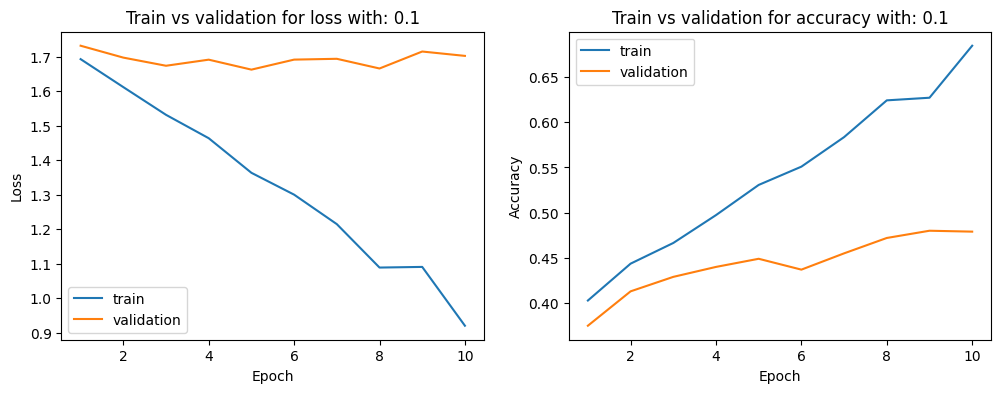

Iteration 0, loss = 2.3262
Iteration 100, loss = 2.1132
Iteration 200, loss = 1.9649
Iteration 300, loss = 1.9884
Iteration 400, loss = 1.8482
Iteration 500, loss = 1.9909
Iteration 600, loss = 1.9513
Iteration 700, loss = 1.7959
Checking accuracy on validation set
Got 17281 / 49000 correct (35.27)
Loss=1.89
Checking accuracy on validation set
Got 361 / 1000 correct (36.10)
Loss=1.89
Iteration 0, loss = 1.8067
Iteration 100, loss = 1.7538
Iteration 200, loss = 2.0466
Iteration 300, loss = 1.9112
Iteration 400, loss = 1.8461
Iteration 500, loss = 1.9679
Iteration 600, loss = 1.9219
Iteration 700, loss = 1.8419
Checking accuracy on validation set
Got 18457 / 49000 correct (37.67)
Loss=1.83
Checking accuracy on validation set
Got 383 / 1000 correct (38.30)
Loss=1.84
Iteration 0, loss = 1.7314
Iteration 100, loss = 1.8609
Iteration 200, loss = 1.9626
Iteration 300, loss = 1.8770
Iteration 400, loss = 1.7554
Iteration 500, loss = 1.9034
Iteration 600, loss = 1.7178
Iteration 700, loss = 1.8

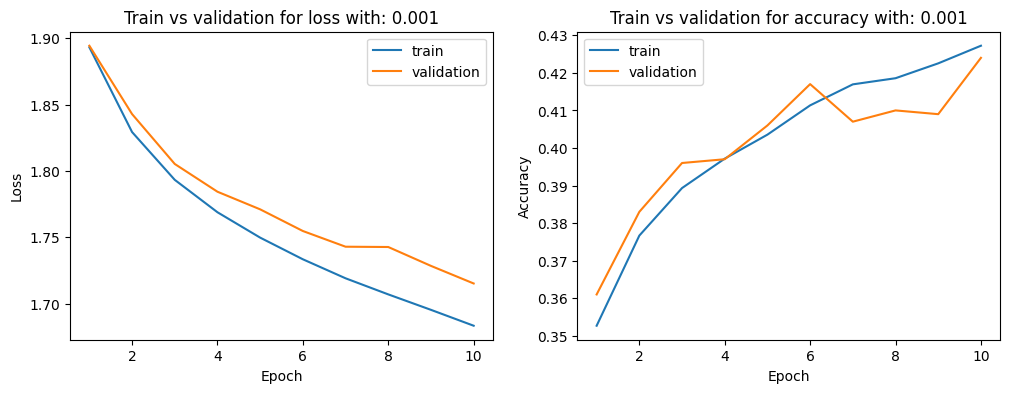

Iteration 0, loss = 2.3234
Iteration 100, loss = 2.3431
Iteration 200, loss = 2.3509
Iteration 300, loss = 2.3166
Iteration 400, loss = 2.3173
Iteration 500, loss = 2.3024
Iteration 600, loss = 2.2882
Iteration 700, loss = 2.2940
Checking accuracy on validation set
Got 6025 / 49000 correct (12.30)
Loss=2.30
Checking accuracy on validation set
Got 105 / 1000 correct (10.50)
Loss=2.30
Iteration 0, loss = 2.2944
Iteration 100, loss = 2.2880
Iteration 200, loss = 2.2943
Iteration 300, loss = 2.3184
Iteration 400, loss = 2.3215
Iteration 500, loss = 2.2809
Iteration 600, loss = 2.2921
Iteration 700, loss = 2.2725
Checking accuracy on validation set
Got 8885 / 49000 correct (18.13)
Loss=2.27
Checking accuracy on validation set
Got 158 / 1000 correct (15.80)
Loss=2.27
Iteration 0, loss = 2.2848
Iteration 100, loss = 2.2546
Iteration 200, loss = 2.2555
Iteration 300, loss = 2.2292
Iteration 400, loss = 2.2940
Iteration 500, loss = 2.2768
Iteration 600, loss = 2.1882
Iteration 700, loss = 2.249

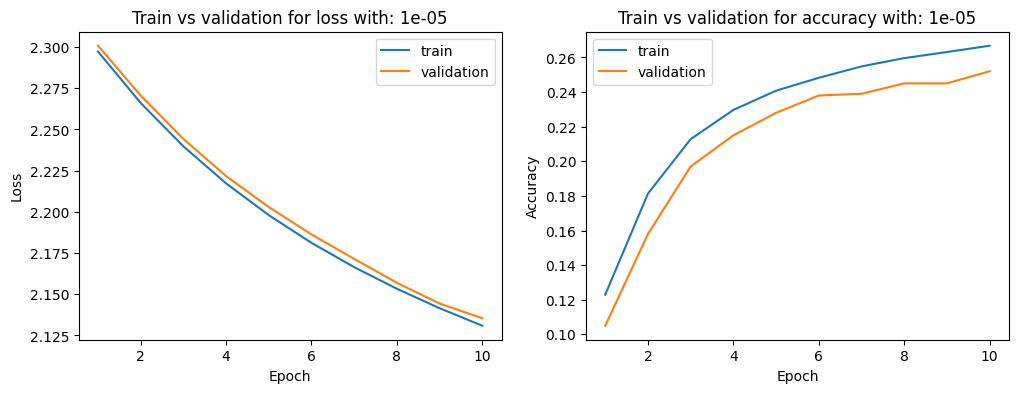

In [ ]:
##############################################################
# - - - WRITE YOUR CODE HERE - - -
# 2) Perform the training stage during 10 epochs, using three
# different learning rate values: 1e-1, 1e-3 and 1e-5.
##############################################################
hidden_layer_size = 4000
learning_rate = [1e-1, 1e-3,1e-5]

for lr in learning_rate:
  ### TO COMPLETE (FCNet3)
  model = FCNet3(
    input_size=32 * 32 * 3, # número de valores de entrada por imagen. CIFAR-10 tiene imágenes de 32*32 píxeles y 3 canales de color, así que, al aplanarlas, tenemos 32*32*3 = 3072 valores.
    hidden_size=hidden_layer_size,
    num_classes=10
  )
  ### TO COMPLETE
  optimizer = torch.optim.SGD(
    model.parameters(), # le indica al optimizador qué parámetros entrenables debe actualizar. Así incluye los de las dos capas ocultas y los de salida.
    lr
  )

  training_loop_plot(model, optimizer, epochs=10)



Iteration 0, loss = 2.3009
Iteration 100, loss = 2.1322
Iteration 200, loss = 1.8894
Iteration 300, loss = 1.7533
Iteration 400, loss = 1.8323
Iteration 500, loss = 1.8458
Iteration 600, loss = 1.6684
Iteration 700, loss = 1.8326
Checking accuracy on validation set
Got 20220 / 49000 correct (41.27)
Loss=1.67
Checking accuracy on validation set
Got 400 / 1000 correct (40.00)
Loss=1.71
Iteration 0, loss = 1.5709
Iteration 100, loss = 1.9782
Iteration 200, loss = 1.6153
Iteration 300, loss = 1.8573
Iteration 400, loss = 1.7027
Iteration 500, loss = 1.6590
Iteration 600, loss = 1.3403
Iteration 700, loss = 1.5964
Checking accuracy on validation set
Got 22317 / 49000 correct (45.54)
Loss=1.56
Checking accuracy on validation set
Got 429 / 1000 correct (42.90)
Loss=1.65
Iteration 0, loss = 1.6680
Iteration 100, loss = 1.6007
Iteration 200, loss = 1.5312
Iteration 300, loss = 1.5994
Iteration 400, loss = 1.4765
Iteration 500, loss = 1.5924
Iteration 600, loss = 1.8280
Iteration 700, loss = 1.5

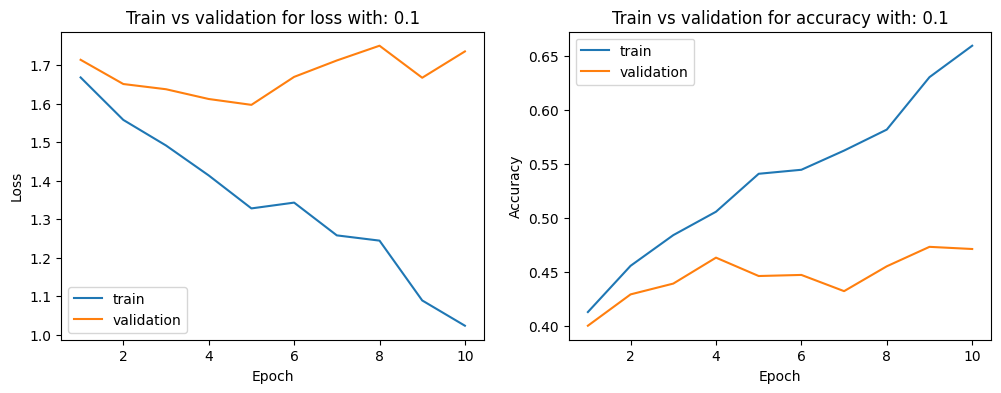

Checking accuracy on test set
Got 4666 / 10000 correct (46.66)
Loss=1.74
Test accuracy: 46.66%  |  Test loss: 1.74


In [ ]:
##############################################################
# - - - WRITE YOUR CODE HERE - - -
# 3) Classify the test set using the model obtained with the
# optimal value for the learning rate. Determine the loss
# and the accuracy obtained over it.
##############################################################
hidden_layer_size = 4000
learning_rate = 1e-1


### TO COMPLETE (FCNet3)
model = FCNet3(
  input_size=32 * 32 * 3, # número de valores de entrada por imagen. CIFAR-10 tiene imágenes de 32*32 píxeles y 3 canales de color, así que, al aplanarlas, tenemos 32*32*3 = 3072 valores.
  hidden_size=hidden_layer_size,
  num_classes=10
)
### TO COMPLETE
optimizer = torch.optim.SGD(
  model.parameters(), # le indica al optimizador qué parámetros entrenables debe actualizar. Así incluye los de las dos capas ocultas y los de salida.
  lr=learning_rate
)

training_loop_plot(model, optimizer, epochs=10)

acc_test, loss_test = eval_model(loader_test, model)
print(f"Test accuracy: {acc_test*100:.2f}%  |  Test loss: {loss_test:.2f}")






---
## 4. CONVOLUTIONAL NEURAL NETWORKS
---

In the second part of the lab session we are going to deal with Convolutional Neural Networks (CNNs). These networks usually combine convolutional and pooling layers.


## **Module API**

---
### 4.1 NEURAL NETWORK DEFINITION
---

The following figure shows the AlexNet model, composed of 8 layers (5 convolutional layers and 3 FC layers).

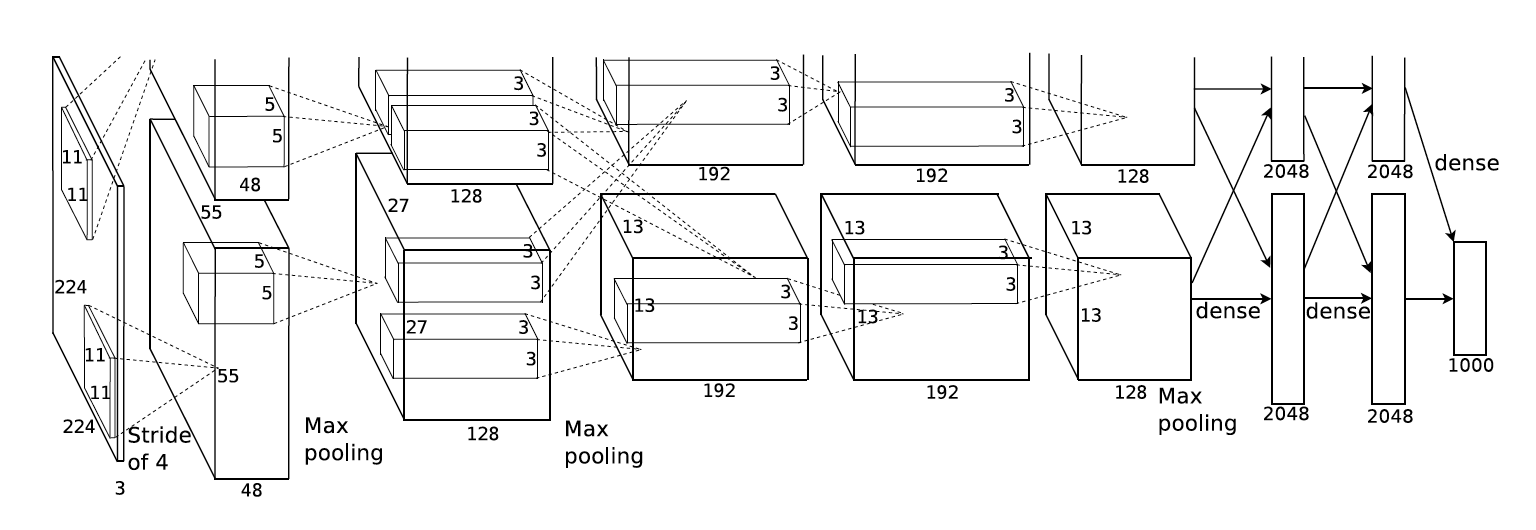

Now we will implement a modified version of AlexNet to perform the multi-class classification problem posed by CIFAR-10 database.

The structure of the modified version to be implemented is the following:

* Input are RGB images of size 32x32x3, as same as in CIFAR-10 database.
* Then, a convolutional layer with 96 filters of size 11x11 is added, whose output results in 96 feature maps of size 32x32.
* After, a maxpooling layer downsamples the 96 feature maps to 16x16.
* Then, a convolutional layer with 256 filters of size 5x5 is added, whose output results in 256 feature maps of size 16x16.
* After, a maxpooling layer downsamples the 256 feature maps to 8x8.
* Then, a convolutional layer with 384 filters of size 3x3 is added, whose output results in 384 feature maps of size 8x8.
* Then, a convolutional layer with 384 filters of size 3x3 is added, whose output results in 384 feature maps of size 8x8.
* Then, a convolutional layer with 256 filters of size 3x3 is added, whose output results in 256 feature maps of size 8x8.
* After, a maxpooling layer downsamples the 256 feature maps to 4x4.
* Finally, 3 dense or FC layers with 4096, 4096 and 10 neurons (output) are included.

Note that behind each convolutional or dense layer (except for the last dense layer) there must be a ReLU activation function.

The only modification with respect to the original structure of the model we will make is the introduction of zero-padding in convolutional layers, in order to preserve the dimensions of the inputs to these layers at the output.


---
### [EXERCISE 6]
---

It's your turn to implement an AlexNet CNN model!

After you implement the AlexNet CNN model, the `test_AlexNet` function will run your implementation; it should print `(64, 10)` for the shape of the output scores.



In [ ]:
class AlexNet(nn.Module):
    def __init__(self, in_channel, num_classes):
        super().__init__()
        ########################################################################
        # TODO: Set up the layers you need for an AlexNet CNN with the         #
        # architecture defined above.                                          #
        ########################################################################
        # - - - WRITE YOUR CODE HERE - - -
        self.conv1 = nn.Conv2d(in_channel, 96, kernel_size=11, padding=5) # out = in + 2*padding - kernel +1 -> 32 = 32 +2*pading -11 +1 -> padding=5 for stride 1.
        self.mxp1 = nn.MaxPool2d(kernel_size=2,stride=2) # out = (size - kernel)/stride +1 -> For kernel=2 and stride=2 it works.
        self.conv2 = nn.Conv2d(in_channels=96, out_channels=256, kernel_size=5, padding=2) # 16 = 16 + 2*padding - kernel +1 -> padding = 2
        self.mxp2 = nn.MaxPool2d(kernel_size=2, stride=2) # out = (size - kernel)/stride +1 -> 8 = (16 - kernel)/stride +1 -> Kernel =2 and stride =2
        self.conv3 = nn.Conv2d(in_channels=256, out_channels=384, kernel_size=3, padding=1) # out = in + 2*padding - kernel +1 -> 8 = 8 +2*pading -3 +1 -> padding=1 for stride 1.
        self.conv4 = nn.Conv2d(in_channels=384, out_channels=384, kernel_size=3, padding=1) # out = in + 2*padding - kernel +1 -> 8 = 8 +2*pading -3 +1 -> padding=1 for stride 1.
        self.conv5 = nn.Conv2d(in_channels=384, out_channels=256, kernel_size=3, padding=1) # out = in + 2*padding - kernel +1 -> 8 = 8 +2*pading - 3 +1 -> padding=1 for stride 1.
        self.mxp3 = nn.MaxPool2d(kernel_size=2, stride=2) # out = (size-kernel)/stride +1 -> 4=(8-kernel)/stride +1 -> kernel =2 and stride =2
        self.fc1 = nn.Linear(in_features=4096, out_features=4096) # in_features = 256*4*4 = 4096
        self.fc2 =nn.Linear(in_features=4096,out_features=4096)
        self.fc3_out = nn.Linear(in_features=4096,out_features=num_classes)

        ########################################################################
        #                          END OF YOUR CODE                            #
        ########################################################################

    def forward(self, x):
        scores = None
        ########################################################################
        # TODO: Implement the forward function for an AlexNet CNN. You         #
        # should use the layers you defined in __init__ and specify the        #
        # connectivity of those layers in forward()                            #
        ########################################################################
        # - - - WRITE YOUR CODE HERE - - -
        x = F.relu(self.conv1(x))
        x = self.mxp1(x)
        x = F.relu(self.conv2(x))
        x = self.mxp2(x)
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = F.relu(self.conv5(x))
        x = self.mxp3(x)
        x = flatten(x)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        scores = self.fc3_out(x)




        ########################################################################
        #                             END OF YOUR CODE                         #
        ########################################################################
        return scores


def test_AlexNet():
    x = torch.zeros((64, 3, 32, 32), dtype=torch.float32)  # minibatch size 64, image size [3, 32, 32]
    model = AlexNet(in_channel=3, num_classes=10)
    scores = model(x)
    print(scores.size())  # you should see [64, 10]

test_AlexNet()

torch.Size([64, 10])


---
### 4.2 TRAINING LOOP AND EXECUTION
---

**Training loop**

You can train the CNN using the training loop defined for the MLP above (see Section 3).

**Execution**

You should now use the Module API to train AlexNet on CIFAR. This should look very similar to training FCNet3!

---
### [EXERCISE 7]
---

a) Use your `AlexNet` class to instantiate a model. Indicate the input size and number of classes (i.e. output size).

b) We will train the model using Stochastic Gradient Descent (SGD) without momentum. Define the optimizer which tracks all the learnable parameters inside `AlexNet`.

c) Perform the training stage during the optimum number of epochs, using an appropriate learning rate.

d) Classify the test set using the model obtained. Determine the loss and the accuracy obtained over it.

e) How is the performance compared with the FCNet?

Iteration 0, loss = 2.3020
Iteration 100, loss = 2.1571
Iteration 200, loss = 1.9954
Iteration 300, loss = 2.0583
Iteration 400, loss = 1.8556
Iteration 500, loss = 2.1541
Iteration 600, loss = 1.6753
Iteration 700, loss = 1.4571
Checking accuracy on validation set
Got 20266 / 49000 correct (41.36)
Loss=1.60
Checking accuracy on validation set
Got 407 / 1000 correct (40.70)
Loss=1.60
Iteration 0, loss = 1.6431
Iteration 100, loss = 1.6834
Iteration 200, loss = 1.4692
Iteration 300, loss = 1.3771
Iteration 400, loss = 1.4208
Iteration 500, loss = 1.4623
Iteration 600, loss = 1.6168
Iteration 700, loss = 1.2350
Checking accuracy on validation set
Got 26573 / 49000 correct (54.23)
Loss=1.28
Checking accuracy on validation set
Got 545 / 1000 correct (54.50)
Loss=1.25
Iteration 0, loss = 1.2411
Iteration 100, loss = 1.2064
Iteration 200, loss = 1.3408
Iteration 300, loss = 1.1552
Iteration 400, loss = 1.0941
Iteration 500, loss = 1.1808
Iteration 600, loss = 0.9735
Iteration 700, loss = 1.0

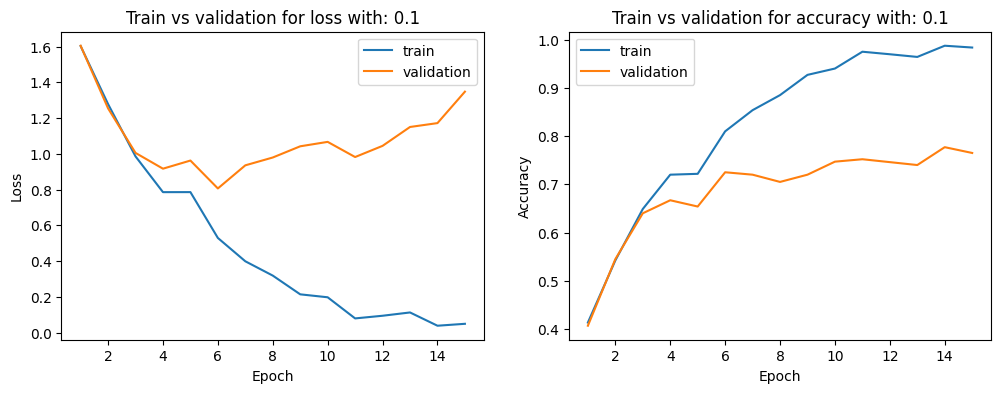

In [ ]:
##############################################################
# - - - WRITE YOUR CODE HERE - - -
##############################################################
learning_rate = 1e-1

model = AlexNet(in_channel=3, num_classes=10)

optimizer = torch.optim.SGD(
  model.parameters(), # le indica al optimizador qué parámetros entrenables debe actualizar. Así incluye los de las dos capas ocultas y los de salida.
  lr=learning_rate
)

training_loop_plot(model, optimizer, epochs=15, device=torch.device('cuda'))


ANSWER (7c): In a preliminary run with lr = 1e-3, whose results are not saved in this notebook, the network stayed close to random guessing (loss ≈ 2.30) for many epochs and was still far from converged after 15 epochs; I therefore consider it too small for this network. This is consistent with Exercise 5, where 1e-3 also learned much slowly than 1e-1 for FCNet3. The choice of lr = 1e-1 is supported by the results saved below: with it, the validation accuracy was already 54.5% after 2 epochs and 72.5% after 6.

To choose the number of epochs, I trained the network for 15 epochs with lr = 1e-1 and observed the training and validation curves. The training loss kept decreasing until it was almost zero (98% training accuracy), but the validation loss reached its minimum at epoch 6 (loss 0.81, accuracy 72.5%) and then increased up to 1.35, which is a clear sign of overfitting, the model is memorizing the training set instead of generalizing. Therefore, I select 6 epochs as the optimal number. It is true that the validation accuracy reaches slightly higher values in later epochs (up to ~77%), but the validation set has only 1000 images, so that measure is noisy, and training longer would produce a heavily overfitted model.

Iteration 0, loss = 2.3008
Iteration 100, loss = 2.1277
Iteration 200, loss = 1.9080
Iteration 300, loss = 1.8909
Iteration 400, loss = 1.8365
Iteration 500, loss = 1.7419
Iteration 600, loss = 1.8339
Iteration 700, loss = 1.5523
Checking accuracy on validation set
Got 20952 / 49000 correct (42.76)
Loss=1.55
Checking accuracy on validation set
Got 437 / 1000 correct (43.70)
Loss=1.54
Iteration 0, loss = 1.6940
Iteration 100, loss = 1.5185
Iteration 200, loss = 1.4294
Iteration 300, loss = 1.2850
Iteration 400, loss = 1.3074
Iteration 500, loss = 1.3201
Iteration 600, loss = 1.3599
Iteration 700, loss = 1.6959
Checking accuracy on validation set
Got 26492 / 49000 correct (54.07)
Loss=1.27
Checking accuracy on validation set
Got 538 / 1000 correct (53.80)
Loss=1.29
Iteration 0, loss = 1.4750
Iteration 100, loss = 1.1298
Iteration 200, loss = 1.2111
Iteration 300, loss = 1.2610
Iteration 400, loss = 1.2154
Iteration 500, loss = 1.0830
Iteration 600, loss = 1.0004
Iteration 700, loss = 1.2

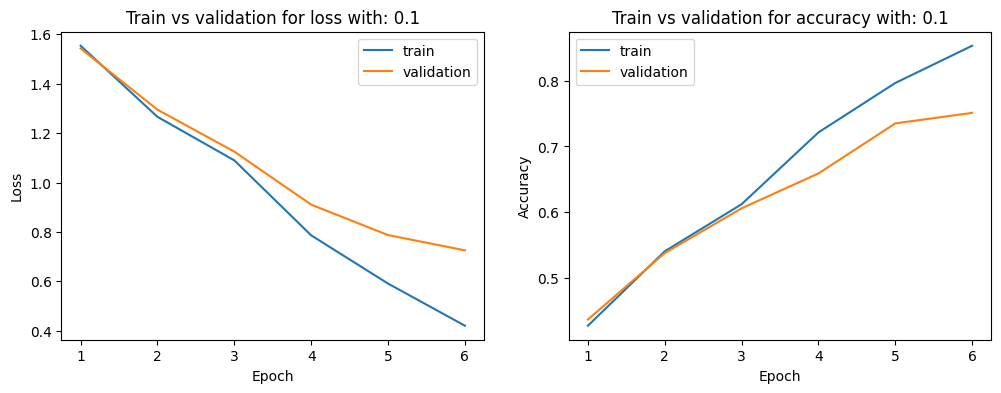

In [ ]:
learning_rate = 1e-1
model = AlexNet(in_channel=3, num_classes=10)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
training_loop_plot(model, optimizer, epochs=6, device=torch.device('cuda'))

In [ ]:
acc_test, loss_test = eval_model(loader_test, model, device=torch.device('cuda'))
print(f"Test accuracy: {acc_test*100:.2f}%  |  Test loss: {loss_test:.2f}")

Checking accuracy on test set
Got 7362 / 10000 correct (73.62)
Loss=0.78
Test accuracy: 73.62%  |  Test loss: 0.78


ANSWER (7d): The loss on the test set is 0.78 and the accuracy is 73.62% (7362 out of 10000 images). These values were measured only once, with the model trained for 6 epochs with lr = 1e-1. They are very close to the validation results at the end of training (75.1% accuracy, loss 0.73), so the validation set was a reliable estimate of the performance on unseen data.

ANSWER (7e): The CNN performs much better than the FCNet. With the FCNet (lr = 1e-1, 10 epochs) the test accuracy was 46.66% and the test loss 1.74, while the AlexNet reaches 73.62% and 0.78, that is, about 27 percentage points more on accuracy and less than half for the loss, in fewer epochs. The reason is that the FCNet flattens the image and treats every pixel independently, so it ignores the spatial structure. Convolutional layers apply small filters shared across the whole image, so they can detect local patterns. The price is a much heavier model (more layers and parameters), which is slower to train and overfits quickly, as seen in the 15-epoch run.

---
### 4.3 SHOW WHAT HAS BEEN LEARNED BY THE CNN
---

Now we will visualize the geometric shapes that the neurons in the first hidden layer have learned to identify, as well as their corresponding activations for some example images. For that purpose, we will use Matplotlib.

---
### Visualize the learned filters and activation maps
---

We have implemented two interesting visualizations for you:

a) Visualize the filters learned in the first convolutional layer.

b) Given a random image as input, visualize the activation maps in the first convolutional layer.

You don't have to code anything for this section. Just execute and understand the code.

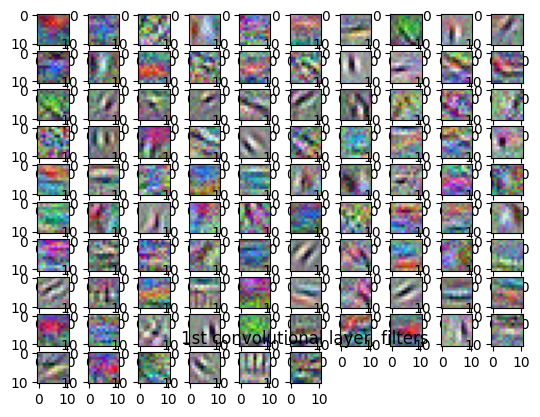

/tmp/ipykernel_1200/2483375271.py:7: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  img = (img * std) + mean # reverse the operation Inorm = (Iorig - mu)/sigma


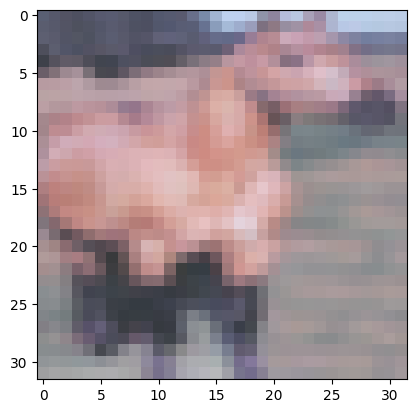

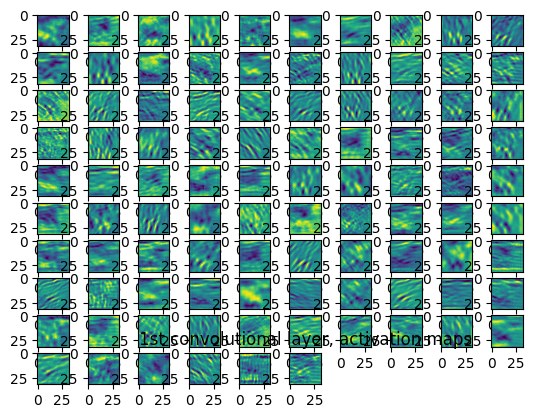

In [ ]:
# a)
# 1st convolutional layer
plt.figure(1)
cont = 1
for i in np.arange(96):
  weight_matrix = model.conv1.weight.cpu().detach().numpy()[i]
  weight_matrix = (weight_matrix-np.min(weight_matrix))/(np.max(weight_matrix)-np.min(weight_matrix))
  weight_matrix = np.transpose(weight_matrix,(1,2,0))
  plt.subplot(10,10,cont)
  cont+=1
  plt.imshow(weight_matrix)
plt.title('1st convolutional layer, filters')
plt.show()

# b)
# Visualize feature maps
activation = {}
def get_activation(name):
    def hook(model, input, output):
        activation[name] = output.detach()
    return hook

model.conv1.register_forward_hook(get_activation('conv1'))
model.conv2.register_forward_hook(get_activation('conv2'))
data = next(iter(loader_val))[0][0] # first image in first batch
data = data.unsqueeze_(0).to(device=torch.device('cuda'), dtype=torch.float32)
output = model(data)

# Image
plt.figure(3)
imshow(data[0].cpu())
plt.show()

# 1st convolutional layer
act_conv1 = activation['conv1'].squeeze()
plt.figure(4)
cont = 1
for idx in np.arange(96):
    plt.subplot(10,10,cont)
    cont+=1
    plt.imshow(act_conv1[idx].cpu().numpy())
plt.title('1st convolutional layer, activation maps')
plt.show()